# 02 – Data Cleaning: Texas PM2.5 and Ozone (2020–2024)

Based on the audit (`01_data_audit.ipynb`), the data has no errors to fix, but it is **not ready for analysis as it is**. We make three changes:

1. **Keep only the analysis rows** – remove PM2.5 rows that repeat the same day, and ozone rows with exceptional-event hours removed.
2. **Remove incomplete ozone days** – days with less than 75% of the 8-hour averages available.
3. **One value per site per day** – average PM2.5 sites that have more than one monitor.

The original and combined files are **not changed**. The cleaned data is saved as new files in `Cleaned_Data/`.

## 0. Load the combined files

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
DATA = ".."

# keep_default_na=False so EPA's event_type "None" is not read as missing
pm = pd.read_csv(f"{DATA}/Combined_Datasets/Texas_PM25_Combined.csv",
                 keep_default_na=False, na_values=[""], low_memory=False)
oz = pd.read_csv(f"{DATA}/Combined_Datasets/Texas_Ozone_Combined.csv",
                 keep_default_na=False, na_values=[""], low_memory=False)

print("PM2.5:", pm.shape)
print("Ozone:", oz.shape)

PM2.5: (164219, 34)
Ozone: (129633, 34)


In [2]:
# keep track of the row counts after each step
steps = []
steps.append({"step": "0. Combined file", "PM2.5 rows": len(pm), "Ozone rows": len(oz)})

## Step 1 – Keep only the analysis rows

- **PM2.5:** continuous monitors have a `1 HOUR` row *and* a `24-HR BLK AVG` row for the same day. The audit showed they hold the same measurement, so using both would count every day twice. We keep the official daily average.
- **Ozone:** on 16 monitor-days EPA published two versions – with the exceptional-event hours **Included** and **Excluded**. We keep the Included version (the air people actually breathed).

These rows already have `analysis_record = FALSE`, so we just filter on that column.

In [3]:
print("PM2.5 rows being removed, by type:")
print(pm[~pm["analysis_record"]]["sample_duration"].value_counts())
print()
print("Ozone rows being removed, by type:")
print(oz[~oz["analysis_record"]]["event_type"].value_counts())

PM2.5 rows being removed, by type:
sample_duration
1 HOUR    80356
Name: count, dtype: int64

Ozone rows being removed, by type:
event_type
Excluded    16
Name: count, dtype: int64


In [4]:
pm1 = pm[pm["analysis_record"]].copy()
oz1 = oz[oz["analysis_record"]].copy()

print("PM2.5:", len(pm), "->", len(pm1), "rows  (removed", len(pm) - len(pm1), ")")
print("Ozone:", len(oz), "->", len(oz1), "rows  (removed", len(oz) - len(oz1), ")")
steps.append({"step": "1. Analysis rows only", "PM2.5 rows": len(pm1), "Ozone rows": len(oz1)})

PM2.5: 164219 -> 83863 rows  (removed 80356 )
Ozone: 129633 -> 129617 rows  (removed 16 )


In [5]:
# check: no "1 HOUR" rows and no "Excluded" rows are left
print("PM2.5 sample durations left:", pm1["sample_duration"].unique())
print("Ozone event types left:", oz1["event_type"].unique())

PM2.5 sample durations left: ['24-HR BLK AVG' '24 HOUR']
Ozone event types left: ['None' 'Included']


## Step 2 – Remove incomplete ozone days

Each ozone day has up to **17** eight-hour averages (EPA's ozone rule uses the averages starting 7 AM to 11 PM).
EPA treats a day as complete when at least **75%** of them were measured – that is 13 of 17.

The audit showed incomplete days read **lower** (median 0.033 vs 0.038 ppm), because the missing hours are often the afternoon when ozone is highest. Keeping them would make some sites and seasons look cleaner than they really are.

(PM2.5 does not need this step – the 24-hour average only exists for complete days.)

In [6]:
oz1.groupby("observation_count").size().tail(6)

observation_count
12      1063
13       825
14       636
15       483
16       321
17    123463
dtype: int64

**Watch out for December 31.** The late 8-hour averages of Dec 31 need hours from Jan 1, which belong to the next year's file.
So on Dec 31 only **12** averages are possible, and `observation_percent` can never be higher than 71%. If we used `observation_percent < 75` directly, we would delete **every** Dec 31 in the data, even fully measured ones.

In [7]:
dec31 = oz1["date_local"].str[5:] == "12-31"
print("Dec 31 rows:", dec31.sum())
print(oz1[dec31].groupby(["observation_count", "observation_percent"]).size())

Dec 31 rows: 354
observation_count  observation_percent
7                  41.0                     1
8                  47.0                     3
10                 59.0                     2
11                 65.0                    68
12                 71.0                   280
dtype: int64


So we compute completeness against what was **possible** that day: 17 averages normally, 12 on Dec 31, and keep days that are at least 75% complete.

In [8]:
oz1["possible_averages"] = 17
oz1.loc[dec31, "possible_averages"] = 12
oz1["percent_complete"] = (100 * oz1["observation_count"] / oz1["possible_averages"]).round(1)

incomplete = oz1["percent_complete"] < 75
print("Incomplete ozone days:", incomplete.sum(), f"({100 * incomplete.mean():.1f}% of rows)")
print("  of these on Dec 31:", (incomplete & dec31).sum())
print("Rows that observation_percent < 75 would have removed:", (oz1["observation_percent"] < 75).sum())
print()
print("Incomplete days per year:")
print(oz1[incomplete].groupby("year").size())

Incomplete ozone days: 3539 (2.7% of rows)
  of these on Dec 31: 4
Rows that observation_percent < 75 would have removed: 3889

Incomplete days per year:
year
2020    605
2021    739
2022    657
2023    691
2024    847
dtype: int64


In [9]:
# where are they? (top sites)
oz1[incomplete].groupby(["site_id", "local_site_name"]).size().sort_values(ascending=False).head(10)

site_id      local_site_name            
48-245-0101  SETRPC  40  Sabine Pass        127
48-245-0022  Hamshire                       119
48-039-1016  Lake Jackson                   118
48-201-0024  Houston Aldine                 101
48-043-0101  Big Bend NP                     96
48-201-1050  Seabrook Friendship Park        77
48-167-1034  Galveston 99th Street           74
48-439-3011  Arlington Municipal Airport     66
48-201-1035  Clinton                         64
48-245-0011  Port Arthur West                64
dtype: int64

In [10]:
oz2 = oz1[~incomplete].copy()
pm2 = pm1.copy()

print("Ozone:", len(oz1), "->", len(oz2), "rows  (removed", len(oz1) - len(oz2), ")")
print("PM2.5 rows below 75% complete:", (pm2["observation_percent"] < 75).sum(), "-> nothing to remove")
steps.append({"step": "2. Complete ozone days only", "PM2.5 rows": len(pm2), "Ozone rows": len(oz2)})

Ozone: 129617 -> 126078 rows  (removed 3539 )


PM2.5 rows below 75% complete: 0 -> nothing to remove


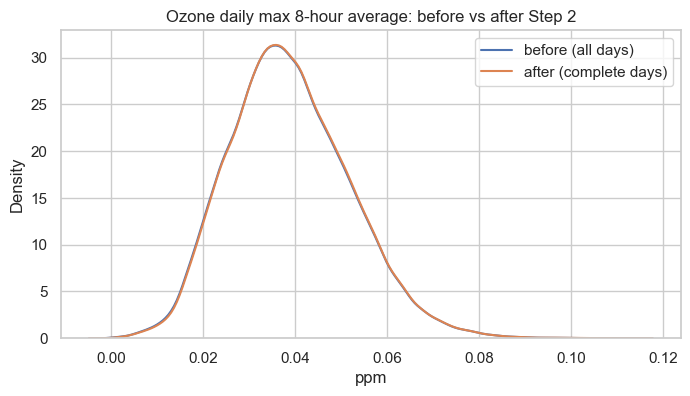

Mean before: 0.0389 | mean after: 0.039


In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(oz1["first_max_value"], label="before (all days)", ax=ax)
sns.kdeplot(oz2["first_max_value"], label="after (complete days)", ax=ax)
ax.set_title("Ozone daily max 8-hour average: before vs after Step 2")
ax.set_xlabel("ppm")
ax.legend()
plt.show()

print("Mean before:", round(oz1["first_max_value"].mean(), 4), "| mean after:", round(oz2["first_max_value"].mean(), 4))

Removing under 3% of the rows barely moves the overall distribution, but it removes a bias for the sites that have many incomplete days.

## Step 3 – One value per site per day

Some PM2.5 sites have two or more monitors (different `poc` numbers) measuring on the same day. These are real, separate instruments, not duplicates – but if we count rows, those sites would get extra weight.
So we **average the monitors** to get one PM2.5 value per site per day.

In [12]:
pm_counts = pm2.groupby(["site_id", "date_local"]).size()
oz_counts = oz2.groupby(["site_id", "date_local"]).size()
print("PM2.5 site-days with more than one monitor:", (pm_counts > 1).sum())
print("Ozone site-days with more than one monitor:", (oz_counts > 1).sum(), "-> ozone is already one row per site-day")

PM2.5 site-days with more than one monitor: 7047
Ozone site-days with more than one monitor: 0 -> ozone is already one row per site-day


In [13]:
# example before averaging
example = pm_counts[pm_counts > 1].index[0]
pm2[(pm2["site_id"] == example[0]) & (pm2["date_local"] == example[1])][
    ["site_id", "date_local", "poc", "method_name", "arithmetic_mean", "aqi"]]

,site_id,date_local,poc,method_name,arithmetic_mean,aqi
1142,48-029-0032,2020-01-04,1,R & P Model 2025 PM-2.5 Sequential Air Sampler...,5.2,29.0
1180,48-029-0032,2020-01-04,2,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,5.6,31.0


In [14]:
site_info = ["county_name", "city_name", "local_site_name", "cbsa_name", "latitude", "longitude"]

pm_clean = pm2.groupby(["site_id", "date_local"]).agg(
    year=("year", "first"),
    county_name=("county_name", "first"),
    city_name=("city_name", "first"),
    local_site_name=("local_site_name", "first"),
    cbsa_name=("cbsa_name", "first"),
    latitude=("latitude", "first"),
    longitude=("longitude", "first"),
    pm25_ugm3=("arithmetic_mean", "mean"),
    pm25_aqi=("aqi", "max"),
    n_monitors=("poc", "count"),
).reset_index()

pm_clean["pm25_ugm3"] = pm_clean["pm25_ugm3"].round(2)
print("PM2.5:", len(pm2), "->", len(pm_clean), "rows  (", len(pm2) - len(pm_clean), "monitor rows combined into their site-day)")
pm_clean[(pm_clean["site_id"] == example[0]) & (pm_clean["date_local"] == example[1])]

PM2.5: 83863 -> 76660 rows  ( 7203 monitor rows combined into their site-day)


,site_id,date_local,year,county_name,city_name,local_site_name,cbsa_name,latitude,longitude,pm25_ugm3,pm25_aqi,n_monitors
3348,48-029-0032,2020-01-04,2020,Bexar,Leon Valley,San Antonio Northwest,"San Antonio-New Braunfels, TX",29.515061,-98.620211,5.4,31.0,2


- `pm25_ugm3` = average of the monitors at that site that day
- `pm25_aqi` = the highest AQI of those monitors (EPA reports the worst monitor for a site's daily AQI)
- `n_monitors` = how many monitors were averaged

In [15]:
oz_clean = oz2[["site_id", "date_local", "year"] + site_info +
               ["first_max_value", "arithmetic_mean", "aqi", "percent_complete"]].rename(columns={
    "first_max_value": "ozone_mda8_ppm",
    "arithmetic_mean": "ozone_daily_mean_ppm",
    "aqi": "ozone_aqi",
}).reset_index(drop=True)

steps.append({"step": "3. One row per site-day", "PM2.5 rows": len(pm_clean), "Ozone rows": len(oz_clean)})
print("Ozone:", len(oz_clean), "rows")

Ozone: 126078 rows


For ozone we use `first_max_value` as the main value – it is the **daily maximum 8-hour average (MDA8)**, which is what the ozone standard and the AQI are based on.

## Before and after summary

In [16]:
steps_table = pd.DataFrame(steps)
steps_table

,step,PM2.5 rows,Ozone rows
0,0. Combined file,164219,129633
1,1. Analysis rows only,83863,129617
2,2. Complete ozone days only,83863,126078
3,3. One row per site-day,76660,126078


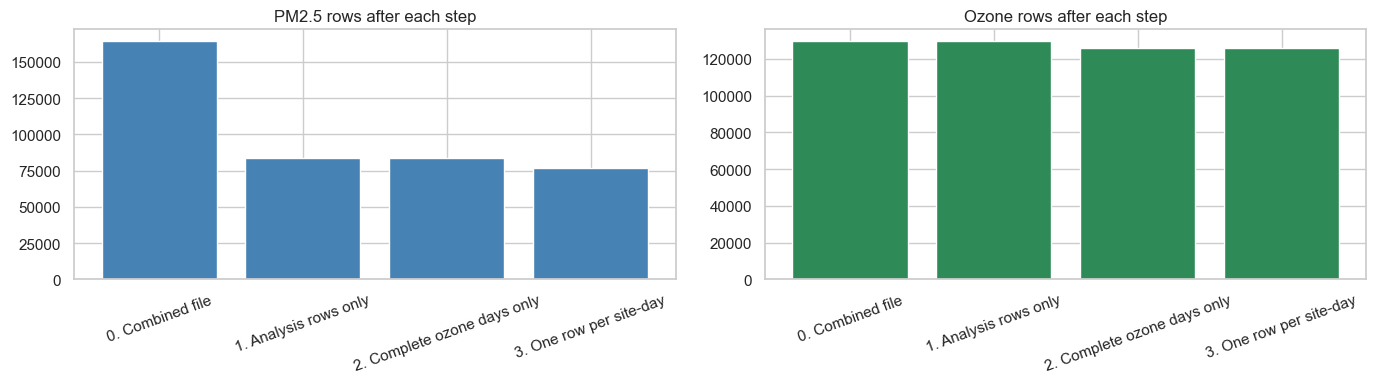

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(steps_table["step"], steps_table["PM2.5 rows"], color="steelblue")
axes[0].set_title("PM2.5 rows after each step")
axes[1].bar(steps_table["step"], steps_table["Ozone rows"], color="seagreen")
axes[1].set_title("Ozone rows after each step")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [18]:
before_after = pd.DataFrame({
    "PM2.5 before": [len(pm), pm["site_id"].nunique(), pm["year"].nunique(), pm["date_local"].nunique()],
    "PM2.5 after": [len(pm_clean), pm_clean["site_id"].nunique(), pm_clean["year"].nunique(), pm_clean["date_local"].nunique()],
    "Ozone before": [len(oz), oz["site_id"].nunique(), oz["year"].nunique(), oz["date_local"].nunique()],
    "Ozone after": [len(oz_clean), oz_clean["site_id"].nunique(), oz_clean["year"].nunique(), oz_clean["date_local"].nunique()],
}, index=["rows", "sites", "years", "distinct dates"])
before_after

,PM2.5 before,PM2.5 after,Ozone before,Ozone after
rows,164219,76660,129633,126078
sites,57,57,76,76
years,5,5,5,5
distinct dates,1827,1827,1827,1827


The row counts drop, but **no site or year is lost**, and every date still has data (thanks to the Dec 31 fix in Step 2).

## Verify the cleaned data

In [19]:
for name, df in [("PM2.5", pm_clean), ("Ozone", oz_clean)]:
    print(name)
    print("  one row per site-day:      ", not df.duplicated(["site_id", "date_local"]).any())
    print("  years:                     ", sorted(df["year"].unique().tolist()))
    print("  year matches date:         ", (df["date_local"].str[:4].astype(int) == df["year"]).all())
    print("  missing values per column: ", df.isna().sum()[df.isna().sum() > 0].to_dict())
    print()

print("All ozone days >= 75% complete:", (oz_clean["percent_complete"] >= 75).all())

PM2.5
  one row per site-day:       True
  years:                      [2020, 2021, 2022, 2023, 2024]
  year matches date:          True
  missing values per column:  {'local_site_name': 1713, 'cbsa_name': 1587}

Ozone
  one row per site-day:       True
  years:                      [2020, 2021, 2022, 2023, 2024]
  year matches date:          True
  missing values per column:  {'cbsa_name': 3709}

All ozone days >= 75% complete: True


In [20]:
# the PM2.5 values should agree with the site-day merged file made earlier (same averaging method)
merged = pd.read_csv(f"{DATA}/Combined_Datasets/Texas_PM25_Ozone_SiteDay_Merged.csv")
check = pm_clean.merge(merged[["site_id", "date_local", "pm25_daily_mean_ugm3"]], on=["site_id", "date_local"])
print("PM2.5 site-days matched:", len(check), "of", len(pm_clean))
print("Largest difference:", (check["pm25_ugm3"] - check["pm25_daily_mean_ugm3"]).abs().max().round(3))

PM2.5 site-days matched: 76660 of 76660
Largest difference: 0.003


The only missing values left are names, not measurements:
- `local_site_name` for one PM2.5 site (48-361-1100, Orange County) – EPA didn't give it a name
- `cbsa_name` for rural counties that are not in any metro area (Brewster, Culberson, Polk)

Small negative values and the very high values (fireworks, Saharan dust, smoke) are real measurements, so we keep them.

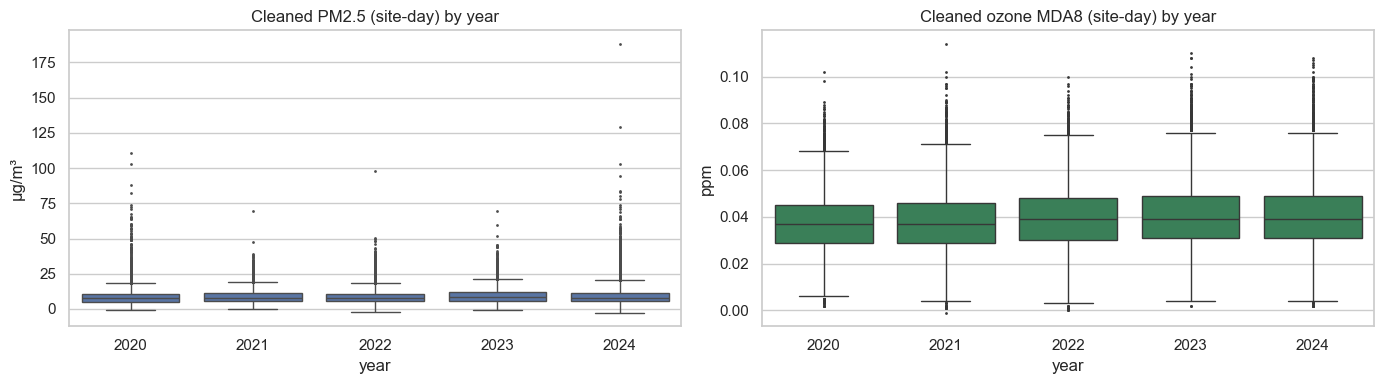

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=pm_clean, x="year", y="pm25_ugm3", ax=axes[0], fliersize=1)
axes[0].set_title("Cleaned PM2.5 (site-day) by year")
axes[0].set_ylabel("µg/m³")
sns.boxplot(data=oz_clean, x="year", y="ozone_mda8_ppm", ax=axes[1], fliersize=1, color="seagreen")
axes[1].set_title("Cleaned ozone MDA8 (site-day) by year")
axes[1].set_ylabel("ppm")
plt.tight_layout()
plt.show()

## Save the cleaned files

In [22]:
os.makedirs(f"{DATA}/Cleaned_Data", exist_ok=True)
pm_clean.to_csv(f"{DATA}/Cleaned_Data/Texas_PM25_Clean.csv", index=False)
oz_clean.to_csv(f"{DATA}/Cleaned_Data/Texas_Ozone_Clean.csv", index=False)

for f in ["Texas_PM25_Clean.csv", "Texas_Ozone_Clean.csv"]:
    print(f, round(os.path.getsize(f"{DATA}/Cleaned_Data/{f}") / 1e6, 1), "MB")

Texas_PM25_Clean.csv 9.6 MB
Texas_Ozone_Clean.csv 17.1 MB


In [23]:
# re-load from disk to make sure the files read back the same
pm_check = pd.read_csv(f"{DATA}/Cleaned_Data/Texas_PM25_Clean.csv")
oz_check = pd.read_csv(f"{DATA}/Cleaned_Data/Texas_Ozone_Clean.csv")
print("PM2.5 file:", pm_check.shape, "| same as in memory:", pm_check.shape == pm_clean.shape)
print("Ozone file:", oz_check.shape, "| same as in memory:", oz_check.shape == oz_clean.shape)
pm_check.head()

PM2.5 file: (76660, 12) | same as in memory: True
Ozone file: (126078, 13) | same as in memory: True


,site_id,date_local,year,county_name,city_name,local_site_name,cbsa_name,latitude,longitude,pm25_ugm3,pm25_aqi,n_monitors
0,48-013-1090,2020-05-29,2020,Atascosa,Lytle,Von Ormy Highway 16,"San Antonio-New Braunfels, TX",29.162892,-98.589146,5.6,31.0,1
1,48-013-1090,2020-05-30,2020,Atascosa,Lytle,Von Ormy Highway 16,"San Antonio-New Braunfels, TX",29.162892,-98.589146,6.3,35.0,1
2,48-013-1090,2020-05-31,2020,Atascosa,Lytle,Von Ormy Highway 16,"San Antonio-New Braunfels, TX",29.162892,-98.589146,9.4,52.0,1
3,48-013-1090,2020-06-01,2020,Atascosa,Lytle,Von Ormy Highway 16,"San Antonio-New Braunfels, TX",29.162892,-98.589146,6.7,37.0,1
4,48-013-1090,2020-06-02,2020,Atascosa,Lytle,Von Ormy Highway 16,"San Antonio-New Braunfels, TX",29.162892,-98.589146,9.2,51.0,1


In [24]:
oz_check.head()

,site_id,date_local,year,county_name,city_name,local_site_name,cbsa_name,latitude,longitude,ozone_mda8_ppm,ozone_daily_mean_ppm,ozone_aqi,percent_complete
0,48-027-1045,2020-01-01,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.032,0.027588,30,100.0
1,48-027-1045,2020-01-02,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.016,0.010176,15,100.0
2,48-027-1045,2020-01-03,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.030,0.026824,28,100.0
3,48-027-1045,2020-01-04,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.039,0.027000,36,100.0
4,48-027-1045,2020-01-05,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.042,0.029706,39,100.0


## Summary

| Step | PM2.5 | Ozone | Why |
|---|---|---|---|
| 1. Analysis rows only | removed 80,356 duplicate `1 HOUR` rows | removed 16 "Excluded" event rows | avoid counting the same day twice |
| 2. Complete ozone days | – | removed 3,539 days under 75% complete (Dec 31 judged out of 12 possible averages) | incomplete days read low |
| 3. One row per site-day | 83,863 monitor rows → 76,660 site-days | already one per site-day | sites with 2+ monitors shouldn't count extra |

**Cleaned files** (in `Cleaned_Data/`):
- `Texas_PM25_Clean.csv` – one row per site per day, `pm25_ugm3` in µg/m³
- `Texas_Ozone_Clean.csv` – one row per site per day, `ozone_mda8_ppm` in ppm, `percent_complete` = share of possible 8-hour averages measured

The original EPA files, the Texas filtered files and the combined files were not changed.